<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/solitons/soliton_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*TASI Lectures on Solitons* — `soliton_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Solitons Ch 3 · Vortices — Figure Notebook
Based on D. Tong, TASI Lectures on Solitons

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
import os

BG   = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
AMB  = '#e8a838'; YELL = '#f9c74f'; GREEN = '#90ee90'
RED  = '#e07070'; PURP = '#c792ea'; BLUE = '#89c4f4'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.25,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMB, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

CH = 'ch03'
os.makedirs(f'figures/{CH}', exist_ok=True)

def save(name, fig):
    fig.savefig(f'figures/{CH}/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'Saved: figures/{CH}/{name}')

print('Setup complete.')


Setup complete.


## Fig 01 · Abrikosov Vortex Profile

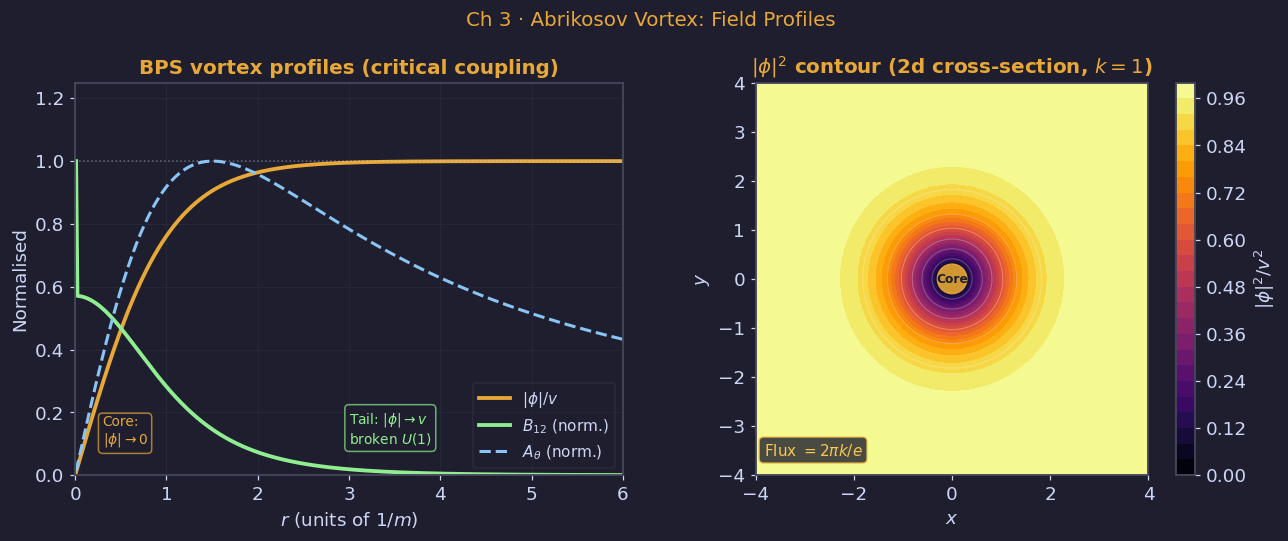

Saved: figures/ch03/fig01_vortex_profile.png


In [2]:
# ── fig01: vortex profile (Abrikosov vortex) ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r"Ch 3 · Abrikosov Vortex: Field Profiles", color=AMB, fontsize=13)

r = np.linspace(0.01, 6.0, 400)
# Approximate BPS profiles: |phi| ~ tanh(r), A_theta ~ (1-sech(r))/r
phi_prof = np.tanh(r)
A_prof   = (1.0 - 1.0/np.cosh(r)) / r
B_prof   = np.gradient(r * A_prof, r) / r   # B = (1/r)d(rA)/dr schematic
B_prof   = np.abs(B_prof); B_prof /= B_prof.max()

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r"BPS vortex profiles (critical coupling)", color=AMB)
ax.plot(r, phi_prof,  color=AMB,  lw=2.5, label=r'$|\phi|/v$')
ax.plot(r, B_prof,    color=GREEN,lw=2.5, label=r'$B_{12}$ (norm.)')
ax.plot(r, A_prof/A_prof.max(), color=BLUE, lw=2.0, ls='--',
        label=r'$A_\theta$ (norm.)')
ax.axhline(1.0, color=FG, ls=':', lw=1, alpha=0.4)
ax.set_xlabel(r'$r$ (units of $1/m$)'); ax.set_ylabel('Normalised')
ax.set_ylim(0, 1.25); ax.set_xlim(0, 6)
ax.legend(fontsize=10); ax.grid(True, alpha=0.2)
ax.text(0.05, 0.08, "Core:\n" + r"$|\phi|\to 0$", transform=ax.transAxes,
        fontsize=9, color=AMB, bbox=dict(boxstyle='round', fc=BG, ec=AMB, alpha=0.7))
ax.text(0.50, 0.08, r"Tail: $|\phi|\to v$" + "\nbroken $U(1)$",
        transform=ax.transAxes, fontsize=9, color=GREEN,
        bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.7))

# Right: 2d contour of |phi|^2
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"$|\phi|^2$ contour (2d cross-section, $k=1$)", color=AMB)
x = np.linspace(-4, 4, 200); y = np.linspace(-4, 4, 200)
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)
phi2 = np.tanh(R)**2
cf = ax2.contourf(X, Y, phi2, levels=25, cmap='inferno')
plt.colorbar(cf, ax=ax2, label=r'$|\phi|^2/v^2$')
ax2.contour(X, Y, phi2, levels=8, colors='white', alpha=0.25, linewidths=0.7)
ax2.add_patch(plt.Circle((0,0), 0.3, color=AMB, zorder=5, alpha=0.9))
ax2.text(0, 0, 'Core', ha='center', va='center', fontsize=8,
         color=BG, fontweight='bold', zorder=6)
ax2.set_xlabel(r'$x$'); ax2.set_ylabel(r'$y$'); ax2.set_aspect('equal')
ax2.text(0.02, 0.05, r'Flux $= 2\pi k/e$', transform=ax2.transAxes,
         fontsize=10, color=YELL,
         bbox=dict(boxstyle='round', fc=BG, ec=YELL, alpha=0.8))
plt.tight_layout()
save('fig01_vortex_profile.png', fig)


## Fig 02 · Vortex 90° Scattering

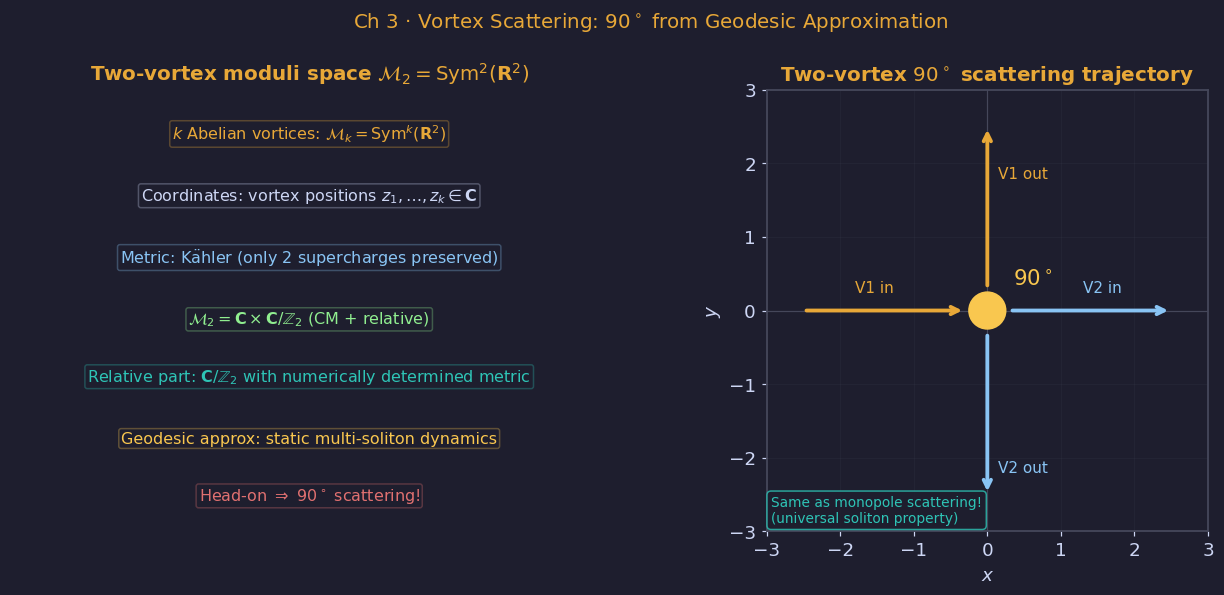

Saved: figures/ch03/fig02_vortex_scattering.png


In [3]:
# ── fig02: vortex 90-degree scattering ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r"Ch 3 · Vortex Scattering: $90^\circ$ from Geodesic Approximation",
             color=AMB, fontsize=13)

# Left: moduli space Sym^2(R^2)
ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r"Two-vortex moduli space $\mathcal{M}_2 = \mathrm{Sym}^2(\mathbf{R}^2)$",
             color=AMB)
items = [
    (0.50, 0.90, r"$k$ Abelian vortices: $\mathcal{M}_k = \mathrm{Sym}^k(\mathbf{R}^2)$", AMB),
    (0.50, 0.76, r"Coordinates: vortex positions $z_1,\ldots,z_k\in\mathbf{C}$", FG),
    (0.50, 0.62, r"Metric: K$\ddot{\rm a}$hler (only 2 supercharges preserved)", BLUE),
    (0.50, 0.48, r"$\mathcal{M}_2 = \mathbf{C}\times\mathbf{C}/\mathbb{Z}_2$ (CM + relative)", GREEN),
    (0.50, 0.35, r"Relative part: $\mathbf{C}/\mathbb{Z}_2$ with numerically determined metric", TEAL),
    (0.50, 0.21, r"Geodesic approx: static multi-soliton dynamics", YELL),
    (0.50, 0.08, r"Head-on $\Rightarrow$ $90^\circ$ scattering!", RED),
]
for (x, y, txt, col) in items:
    ax.text(x, y, txt, ha='center', va='center', fontsize=10.5,
            color=col, transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.30))

# Right: 90-degree scattering
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r"Two-vortex $90^\circ$ scattering trajectory", color=AMB)
ax2.annotate('', xy=(-0.3, 0), xytext=(-2.5, 0),
             arrowprops=dict(arrowstyle='->', color=AMB, lw=2.5))
ax2.annotate('', xy=( 2.5, 0), xytext=( 0.3, 0),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5))
ax2.annotate('', xy=(0,  2.5), xytext=(0,  0.3),
             arrowprops=dict(arrowstyle='->', color=AMB, lw=2.5))
ax2.annotate('', xy=(0, -2.5), xytext=(0, -0.3),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5))
ax2.text(-1.8,  0.25, "V1 in",  color=AMB,  fontsize=10)
ax2.text( 1.3,  0.25, "V2 in",  color=BLUE, fontsize=10)
ax2.text( 0.15, 1.8,  "V1 out", color=AMB,  fontsize=10)
ax2.text( 0.15,-2.2,  "V2 out", color=BLUE, fontsize=10)
ax2.add_patch(plt.Circle((0,0), 0.25, color=YELL, zorder=5))
ax2.text(0.35, 0.35, r"$90^\circ$", fontsize=14, color=YELL)
ax2.set_xlim(-3,3); ax2.set_ylim(-3,3); ax2.set_aspect('equal')
ax2.axhline(0, color=EDGE, lw=0.8); ax2.axvline(0, color=EDGE, lw=0.8)
ax2.set_xlabel(r'$x$'); ax2.set_ylabel(r'$y$'); ax2.grid(True, alpha=0.15)
ax2.text(0.01, 0.02, "Same as monopole scattering!\n(universal soliton property)",
         transform=ax2.transAxes, fontsize=9, color=TEAL,
         bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.8))
plt.tight_layout()
save('fig02_vortex_scattering.png', fig)


## Fig 03 · Brane Construction of Vortices

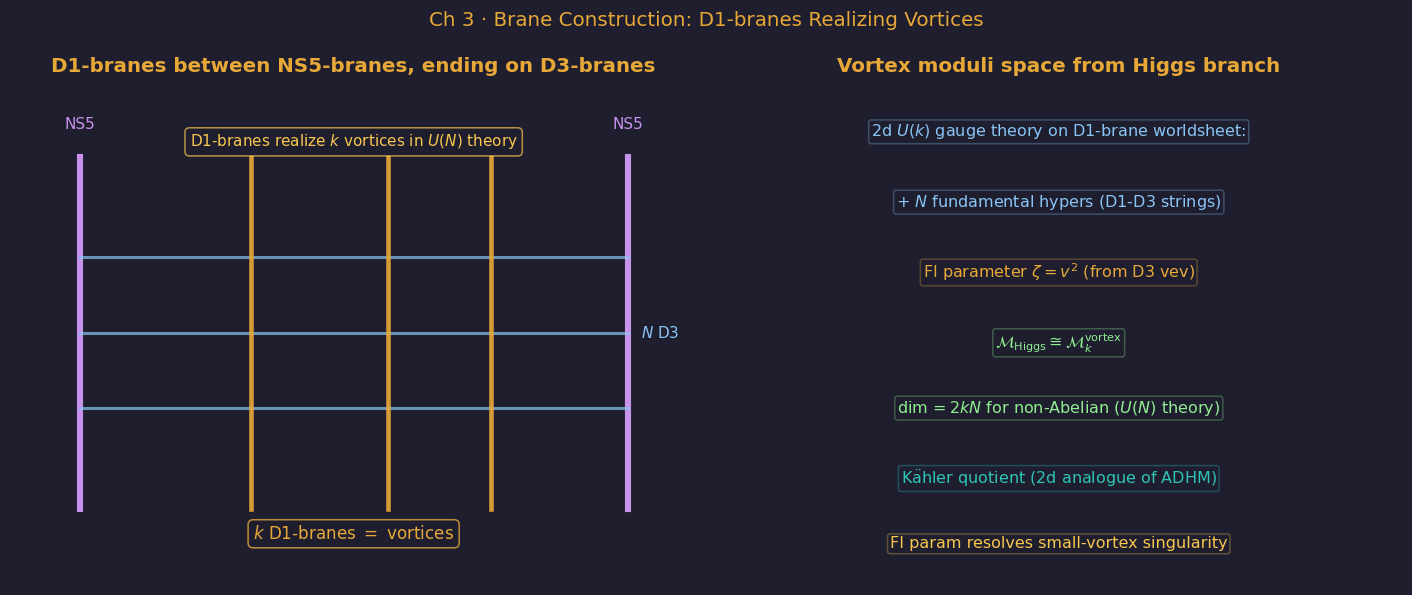

Saved: figures/ch03/fig03_vortex_brane.png


In [4]:
# ── fig03: vortex brane construction (D1 in D3/NS5) ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r"Ch 3 · Brane Construction: D1-branes Realizing Vortices",
             color=AMB, fontsize=13)

# Left: brane picture
ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title("D1-branes between NS5-branes, ending on D3-branes", color=AMB)

# NS5 walls
for xp in [0.10, 0.90]:
    ax.plot([xp, xp], [0.15, 0.85], color=PURP, lw=4, transform=ax.transAxes)
    ax.text(xp, 0.90, "NS5", ha='center', va='bottom', fontsize=10,
            color=PURP, transform=ax.transAxes)

# D3 branes
for y in [0.35, 0.50, 0.65]:
    ax.plot([0.10, 0.90], [y, y], color=BLUE, lw=2, alpha=0.7,
            transform=ax.transAxes)
ax.text(0.92, 0.50, r'$N$ D3', ha='left', va='center', fontsize=10,
        color=BLUE, transform=ax.transAxes)

# D1 strings (vortices)
for xc in [0.35, 0.55, 0.70]:
    ax.plot([xc, xc], [0.15, 0.85], color=AMB, lw=3, alpha=0.9,
            transform=ax.transAxes)
ax.text(0.50, 0.10, r'$k$ D1-branes $=$ vortices', ha='center', va='center',
        fontsize=11, color=AMB, transform=ax.transAxes,
        bbox=dict(boxstyle='round', fc=BG, ec=AMB, alpha=0.8))

ax.text(0.50, 0.88, r'D1-branes realize $k$ vortices in $U(N)$ theory',
        ha='center', va='center', fontsize=10, color=YELL,
        transform=ax.transAxes,
        bbox=dict(boxstyle='round', fc=BG, ec=YELL, alpha=0.7))

# Right: moduli space identification
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r"Vortex moduli space from Higgs branch", color=AMB)
items = [
    (0.50, 0.90, r"2d $U(k)$ gauge theory on D1-brane worldsheet:", BLUE),
    (0.50, 0.76, r"$+$ $N$ fundamental hypers (D1-D3 strings)", BLUE),
    (0.50, 0.62, r"FI parameter $\zeta = v^2$ (from D3 vev)", AMB),
    (0.50, 0.48, r"$\mathcal{M}_{\rm Higgs} \cong \mathcal{M}_k^{\rm vortex}$", GREEN),
    (0.50, 0.35, r"$\dim = 2kN$ for non-Abelian ($U(N)$ theory)", GREEN),
    (0.50, 0.21, r"K$\ddot{\rm a}$hler quotient (2d analogue of ADHM)", TEAL),
    (0.50, 0.08, r"FI param resolves small-vortex singularity", YELL),
]
for (x, y, txt, col) in items:
    ax2.text(x, y, txt, ha='center', va='center', fontsize=10.5,
             color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.30))
plt.tight_layout()
save('fig03_vortex_brane.png', fig)


## Download

In [5]:
import shutil
CH = 'ch03'
shutil.make_archive(f'{CH}_figures', 'zip', f'figures/{CH}')
try:
    from google.colab import files
    files.download(f'{CH}_figures.zip')
except ImportError:
    print(f'Not in Colab — saved to figures/{CH}/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>